In [1]:
######################################################################################################
# ALUNO : 
# MATRÍCULA : 
# TURMA : 
######################################################################################################

In [2]:
######################################################################################################
# ALUNO : Daniel Marques Diniz Maia
# MATRÍCULA : 2026061836
# TURMA : TM
######################################################################################################

**Atividade 0 - Demonstre as equações de regressão linear para uma função y = ax + b usando seus conhecimentos de cálculo.**

$$S(a, b) = \sum_{i=0}^{n} (y_i - a - bx_i)^2$$

Partindo dessa equação, sabemos que temos $n + 1$ pontos (somatório de $0$ a $n$) e as médias são $\bar{x} = \frac{1}{n+1} \sum_{i=0}^{n} x_i$ e $\bar{y} = \frac{1}{n+1} \sum_{i=0}^{n} y_i$. Tomando a derivada parcial em $a$ e igualando a zero, obtemos:

$$ \frac{\partial S}{\partial a} = -2 \sum_{i=0}^{n} (y_i - a - bx_i) = 0 \implies (n+1)a = \sum_{i=0}^{n} y_i - b\sum_{i=0}^{n} x_i \implies a  = \bar{y} - b\bar{x}\quad \text{(Equação 1)} $$

Fazendo o mesmo para $b$:

$$\frac{\partial S}{\partial b} = -2 \sum_{i=0}^{n} x_i(y_i - a - bx_i) = 0 \implies a\sum_{i=0}^{n} x_i + b\sum_{i=0}^{n} x_i^2 = \sum_{i=0}^{n} x_i y_i \quad \text{(Equação 2)}$$

Substituindo o $a$ encontrado na equação 2 e sabendo que $\sum x_i = (n+1)\bar{x}$, obtemos:

$$(\bar{y} - b\bar{x})(n+1)\bar{x} + b\sum_{i=0}^{n} x_i^2 = \sum_{i=0}^{n} x_i y_i \implies (n+1)\bar{x}\bar{y} - b(n+1)\bar{x}^2 + b\sum_{i=0}^{n} x_i^2 = \sum_{i=0}^{n} x_i y_i $$

Isolando b:

$$b \left( \sum_{i=0}^{n} x_i^2 - (n+1)\bar{x}^2 \right) = \sum_{i=0}^{n} x_i y_i - (n+1)\bar{x}\bar{y}$$

Como $(n+1)\bar{y} = \sum_{i=0}^{n} y_i$, podemos reescrever:

$$ b = \frac{\sum_{i=0}^{n} x_i y_i - \bar{x}\sum_{i=0}^{n} y_i}{\sum_{i=0}^{n} x_i^2 - (n+1)\bar{x}^2}$$

Substituindo na equação 1 o $b$ encontrado e fazendo algumas manipulações, obtemos:

$$ a = \frac{\bar{y}\sum_{i=0}^{n} x_i^2 - \bar{x}\sum_{i=0}^{n} x_i y_i}{\sum_{i=0}^{n} x_i^2 - (n+1)\bar{x}^2} $$



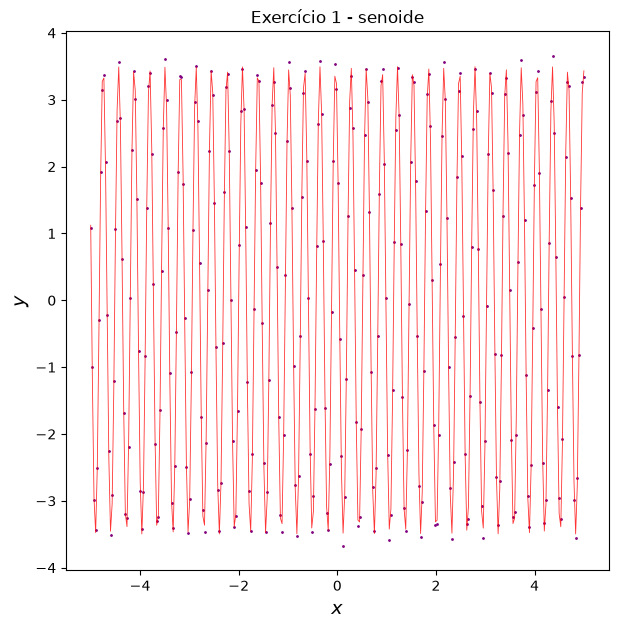

A e B =  -3.4953042176876736 20.000707536735373 -0.8545205630209236


In [3]:
# Atividade 1 - Ajuste de uma curva do tipo : y = a * sin(b*x + c)
# Usando curve_fit from Scipy, modifique os exemplos dados na aula anterior
# para fazer o ajuste pedido

# Importando as bibliotecas e definindo funções que serão úteis

from scipy.optimize import curve_fit as crf
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

def gera_grafico(x,y,titulo,cor):
    fig, ax = plt.subplots(figsize=(7,7))
    ax.set_title(titulo)
    ax.set_xlabel("$x$", fontsize=14)
    ax.set_ylabel("$y$", fontsize=14)
    ax.scatter(x,y,color=cor, s=1)
    return ax

# Gerando os dados com ruído

x = np.linspace(-5,5,300)
def funcao1(x,a,b,c):
    return a*np.sin(b*x+c)
y = funcao1(x,3.5,20,-4)
ruido = 0.1*np.random.normal(size=y.size)
y += ruido


# Criando o gráfico e fazendo o ajuste
ax = gera_grafico(x,y,'Exercício 1 - senoide','purple')
pars, cov = crf(f=funcao1,xdata=x,ydata=y,p0=[2,20.2,-1], bounds=[-np.inf,np.inf])
ax.plot(x, funcao1(x,*pars), lw= 0.6, color='red',alpha=0.8)
plt.show()
print("A e B = ",*pars)

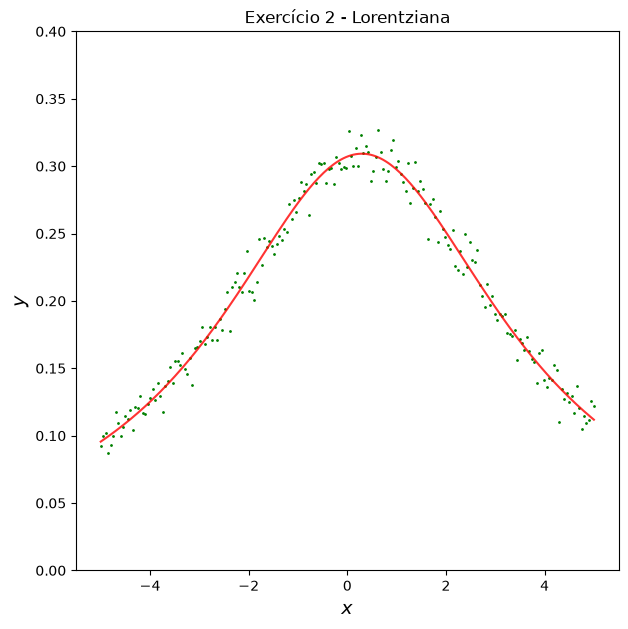

A e B =  3.877919913364953 0.29549420205969085 12.540664347737449


In [4]:
# Atividade 2 - Ajuste de uma curva do tipo : y = a/( (x - b)**2 + c )
# Usando curve_fit from Scipy, modifique os exemplos dados na aula anterior 
# para fazer o ajuste pedido


# Gerando os dados com ruído

x = np.linspace(-5,5,200)
def funcao2(x,a,b,c):
    return a/( (x - b)**2 + c )
y = funcao2(x,4,0.3,13)
ruido = 0.01*np.random.normal(size=y.size)
y += ruido

# Criando o gráfico e fazendo o ajuste

ax = gera_grafico(x,y,'Exercício 2 - Lorentziana','green')
pars, cov = crf(f=funcao2,xdata=x,ydata=y,p0=[2,0.1,10], bounds=[-np.inf,np.inf])
ax.plot(x, funcao2(x,*pars), color='red',alpha=0.8)
ax.set_xlim(-5.5,5.5)
ax.set_ylim(0,0.4)
plt.show()
print("A e B = ",*pars)

# Nota: essa função é extremamente sensível a ruído; ao colocar valores superiores a 0.4 na sua expressão geradora, os dados já ficam muito
# dispersos, dificultando muito a análise da precisão do ajuste

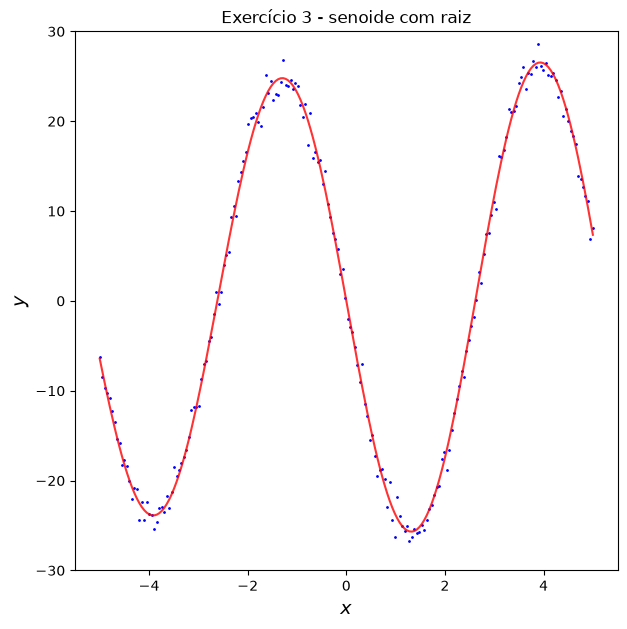

A e B =  -4.137157348823041 1.2011992848287734 37.23384708110247


In [5]:
# Atividade 3 - Ajuste de uma curva do tipo : y = a* sin(b*x)*sqrt(x+c)
# Usando curve_fit from Scipy, modifique os exemplos dados na aula anterior 
# para fazer o ajuste pedido

x = np.linspace(-5,5,200)
def funcao3(x,a,b,c):
    return a*np.sin(b*x)*np.sqrt(x+c)
y = funcao3(x,-4,1.2,40)
ruido = 1*np.random.normal(size=y.size)
y += ruido

# Criando o gráfico e fazendo o ajuste

ax = gera_grafico(x,y,'Exercício 3 - senoide com raiz','blue')
pars, cov = crf(f=funcao3,xdata=x,ydata=y,p0=[-4,1.2,40], bounds=[-np.inf,np.inf])
ax.plot(x, funcao3(x,*pars), color='red',alpha=0.8)
ax.set_xlim(-5.5,5.5)
ax.set_ylim(-30,30)
plt.show()
print("A e B = ",*pars)

# Sensibilidade a ruído muito diferente da função anterior, já que nela, os valores de np.random.normal entre 0 e 1 afetam muito os valores de y

[ 5.54553585e-08  3.46334062e-06 -4.36021275e-03  2.10687577e+00
 -3.25362185e+02]


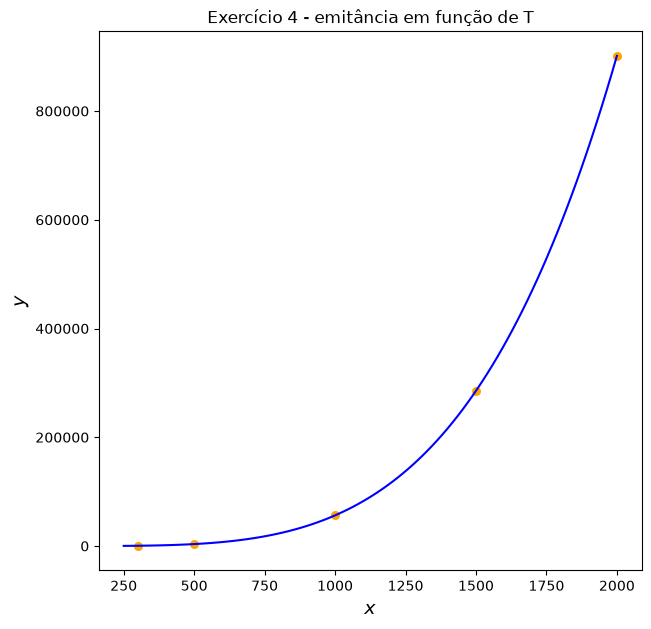

In [6]:
# Atividade 4 - Emitância de um corpo negro em função de T

# Definindo os dados e realizando o ajuste
temperaturas = np.array([300,500,1000,1500,2000])
emitancias = np.array([456.98,3536.9,56340,285456,901440])
coeficientes = np.polyfit(temperaturas,emitancias,4)
funcao_emitancia = np.poly1d(coeficientes)

# erando o gráfico
fig, ax = plt.subplots(figsize=(7,7))
ax.set_title('Exercício 4 - emitância em função de T')
ax.set_xlabel("$x$", fontsize=14)
ax.set_ylabel("$y$", fontsize=14)
ax.scatter(temperaturas,emitancias,color='orange', s=30)
novo_t = np.linspace(250,2000,100)  # corrigindo a quantidade de pontos para tornar visível o grau do polinômio
ax.plot(novo_t, funcao_emitancia(novo_t), color='blue')
print(coeficientes)
plt.show()

A e B =  5.634042348342333e-08 48.33042094441039


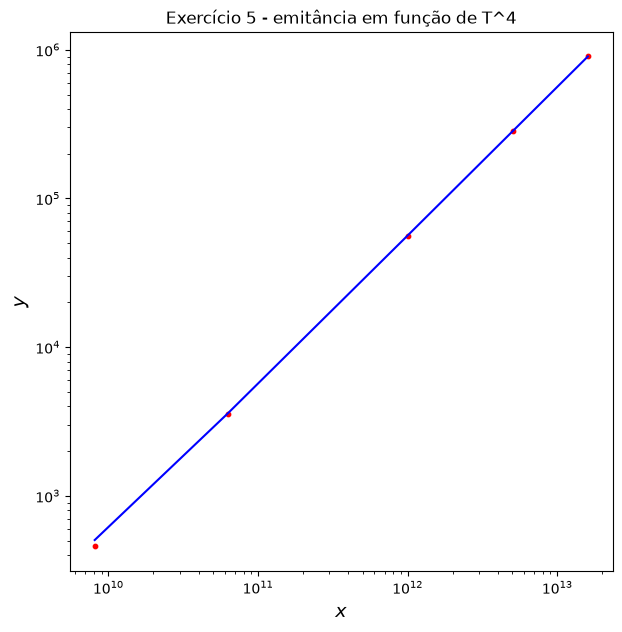

In [7]:
# Atividade 5 - Emitância de um corpo negro em função de T**4

# Definindo os dados
temperaturas = np.array([300,500,1000,1500,2000])
emitancias = np.array([456.98,3536.9,56340,285456,901440])
x = temperaturas**4
def reta(x,a,b):
    return a*x + b

# Gerando o gráfico
fig, ax = plt.subplots(figsize=(7,7))
ax.set_title('Exercício 5 - emitância em função de T^4')
ax.set_xlabel("$x$", fontsize=14)
ax.set_ylabel("$y$", fontsize=14)
ax.scatter(x,emitancias,color='red', s=10)
ax.set_yscale('log')
ax.yaxis.set_major_locator(mpl.ticker.LogLocator(base=10.0))
ax.set_xscale('log')
ax.xaxis.set_major_locator(mpl.ticker.LogLocator(base=10.0))
pars, cov = crf(f=reta,xdata=x,ydata=emitancias,p0=[5,0], bounds=[-np.inf,np.inf])
ax.plot(x, reta(x,*pars),color='blue')
print("A e B = ",*pars)
plt.show()